# Karate Club: LabelPropagation vs GCN

기존 `Karate_club_gcn.ipynb`의 성능 평가를 위한 독립 실행 비교 노트북입니다.


## 비교 조건과 해석

- 원본과 동일한 `KarateClub()`, 34차원 노드 특징, 기본 `train_mask`를 사용합니다.
- 학습 노드 4개를 제외한 **30개 노드 전체**를 `test_mask = ~train_mask`로 평가합니다.
  전체 노드 정확도에는 학습 노드가 포함되므로 주요 지표로 사용하지 않습니다.
- GCN과 MLP는 Adam(lr=0.01, weight_decay=0), CrossEntropyLoss, 401회 갱신을 사용합니다.
  평가 레이블은 손실, 모델 선택, 하이퍼파라미터 선택에 사용하지 않습니다.
- 검증 집합과 조기 종료 없이 미리 정한 마지막 모델을 평가합니다.
  설정을 바꾸어 테스트 성능으로 선택하면 테스트 집합에 과적합할 수 있습니다.
- Accuracy와 Macro-F1을 보고합니다. Macro-F1은 네 클래스의 F1을 같은 비중으로 평균하며,
  해당 클래스의 분모가 0이면 F1을 0으로 정의합니다.
- 시드 10개는 **동일한 분할에서 모델 초기화의 변동**을 측정합니다.
  표준편차는 표본 표준편차이며, 분할 변경에 따른 불확실성이나 신뢰구간이 아닙니다.
  작은 단일 그래프의 결과를 다른 데이터셋 성능으로 일반화하지 않습니다.

두 노트북은 독립 실행이 가능합니다. 커널은 기존 `ai_tutorial` 환경을 선택하고 위에서 아래로 실행하세요.
필요한 패키지는 기존과 같은 `torch`, `torch_geometric`, `matplotlib`, `networkx`, `IPython`입니다.
설치가 필요하면 다음 셀의 주석을 해제해 실행한 뒤 커널을 다시 시작하세요.


In [1]:
# %pip install torch torch_geometric matplotlib networkx ipython


In [2]:
from pathlib import Path
import csv
import json
import platform
import time
import torch
import torch.nn.functional as F
import torch_geometric
import matplotlib.pyplot as plt
import networkx as nx
from IPython.display import display, Markdown
from torch import nn
from torch_geometric.datasets import KarateClub
from torch_geometric.nn import GCNConv
from torch_geometric.utils import to_networkx

# 작은 CPU 그래프에서 스레드 생성 비용을 줄이고 동일 환경에서 재현합니다.
torch.set_num_threads(1)
SEEDS = [1234, 0, 1, 2, 3, 4, 5, 6, 7, 8]
EPOCHS = 401  # 원본 range(401)과 동일한 401회 파라미터 갱신
LEARNING_RATE = 0.01
dataset = KarateClub()
data = dataset[0].cpu()
train_mask = data.train_mask.clone()
test_mask = ~train_mask
NUM_CLASSES = dataset.num_classes
assert train_mask.sum().item() == 4
assert test_mask.sum().item() == 30
assert torch.bincount(data.y[train_mask], minlength=NUM_CLASSES).eq(1).all()
assert torch.equal(data.x, torch.eye(data.num_nodes))
print(f"Nodes={data.num_nodes}, edges={data.num_edges}, classes={NUM_CLASSES}")
print("Train nodes:", train_mask.nonzero(as_tuple=True)[0].tolist())
print(f"Train={int(train_mask.sum())}, test={int(test_mask.sum())}")
print(f"Python={platform.python_version()}, torch={torch.__version__}, PyG={torch_geometric.__version__}")


Nodes=34, edges=156, classes=4
Train nodes: [0, 4, 8, 24]
Train=4, test=30
Python=3.10.21, torch=2.12.0+cpu, PyG=2.8.0.post1


## LabelPropagation: 그래프와 관측 레이블을 사용하는 비교군

노드 특징 `data.x`는 사용하지 않고, 그래프 연결과 4개 학습 노드의 레이블만 사용합니다.
PyG의 `LabelPropagation`으로 대칭 정규화한 인접 행렬 $S=D^{-1/2}AD^{-1/2}$에 대해
$Y^{(t+1)}=\alpha S Y^{(t)}+(1-\alpha)Y^{(0)}$를 100회 반복합니다.
$Y^{(0)}$는 학습 노드만 one-hot이고 나머지는 0입니다. `alpha=0.9`는 평가 전에 고정한 설정입니다.

이는 원래 레이블을 매번 재주입하는 **soft 방식**이며, 학습 노드 값을 매 단계 강제로 고정하는
hard-clamping 방식과 다릅니다. 학습 정확도도 반드시 1이 되지는 않습니다.
기본 PyG 구현처럼 자기 루프를 추가하지 않고 각 단계 점수를 [0, 1]로 제한합니다.
최대 점수의 클래스를 예측하며, 동점이면 `argmax`가 가장 작은 클래스 번호를 선택합니다.

LP에는 optimizer, 역전파, 학습 epoch, 무작위 초기화가 없습니다.
100 propagation steps와 GCN의 401회 갱신은 서로 다른 연산이며 같은 연산 예산을 뜻하지 않습니다.
시간은 CPU의 학습/전파 및 최종 추론 구간만 측정하며 데이터 준비와 시각화는 제외합니다.
동일한 분할에서 LP는 결정적이므로 1회 결과를 보고합니다(표의 sd=0은 단일 실행 표시).

구현 정의: [PyG LabelPropagation 문서](https://pytorch-geometric.readthedocs.io/en/latest/generated/torch_geometric.nn.models.LabelPropagation.html),
[공식 소스](https://pytorch-geometric.readthedocs.io/en/latest/_modules/torch_geometric/nn/models/label_prop.html).


In [3]:
def evaluate(pred, mask):
    target = data.y[mask]
    chosen = pred[mask]
    cm = torch.bincount(
        target * NUM_CLASSES + chosen, minlength=NUM_CLASSES ** 2
    ).reshape(NUM_CLASSES, NUM_CLASSES)
    tp = cm.diag().float()
    denominator = cm.sum(0).float() + cm.sum(1).float()
    f1 = torch.where(denominator > 0, 2 * tp / denominator.clamp_min(1), 0)
    return {
        "accuracy": (target == chosen).float().mean().item(),
        "macro_f1": f1.mean().item(),
        "confusion_matrix": cm.tolist(),
        "per_class_f1": f1.tolist(),
    }


def result_row(name, seed, pred, elapsed, parameters):
    train = evaluate(pred, train_mask)
    test = evaluate(pred, test_mask)
    return dict(model=name, seed=seed, train_accuracy=train["accuracy"],
                test_accuracy=test["accuracy"], test_macro_f1=test["macro_f1"],
                seconds=elapsed, parameters=parameters)


def show_summary(rows):
    summary = []
    header = "| Model | Runs | Train accuracy | Test accuracy (mean ± sd) | Test Macro-F1 (mean ± sd) | Seconds (mean) | Parameters |"
    lines = [header, "|---|---:|---:|---:|---:|---:|---:|"]
    for name in dict.fromkeys(row["model"] for row in rows):
        group = [row for row in rows if row["model"] == name]
        item = {"model": name, "runs": len(group)}
        for key in ["train_accuracy", "test_accuracy", "test_macro_f1", "seconds"]:
            values = torch.tensor([row[key] for row in group], dtype=torch.float64)
            item[key + "_mean"] = values.mean().item()
            item[key + "_sd"] = values.std(unbiased=True).item() if len(group) > 1 else 0.0
        item["parameters"] = group[0]["parameters"]
        summary.append(item)
        lines.append(
            f"| {name} | {len(group)} | {item['train_accuracy_mean']:.3f} | "
            f"{item['test_accuracy_mean']:.3f} ± {item['test_accuracy_sd']:.3f} | "
            f"{item['test_macro_f1_mean']:.3f} ± {item['test_macro_f1_sd']:.3f} | "
            f"{item['seconds_mean']:.4f} | {item['parameters']} |"
        )
    display(Markdown("\n".join(lines)))
    return summary


## 기준 모델: 원본 GCN과 학습 함수

원본 GCN 구조를 복제해 같은 마스크에서 수치 평가합니다. 원본 파일을 실행할 필요는 없습니다.


In [4]:
class GCN(nn.Module):
    # 원본과 동일한 구조. 시드는 생성 직전에 설정합니다.
    def __init__(self):
        super().__init__()
        self.conv1 = GCNConv(dataset.num_features, 4)
        self.conv2 = GCNConv(4, 4)
        self.conv3 = GCNConv(4, 2)
        self.classifier = nn.Linear(2, NUM_CLASSES)

    def forward(self, x, edge_index):
        h = self.conv1(x, edge_index).tanh()
        h = self.conv2(h, edge_index).tanh()
        h = self.conv3(h, edge_index).tanh()
        return self.classifier(h), h


def fit_neural(model):
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    loss_history = []
    started = time.perf_counter()
    model.train()
    for _ in range(EPOCHS):
        optimizer.zero_grad()
        logits, _ = model(data.x, data.edge_index)
        loss = F.cross_entropy(logits[train_mask], data.y[train_mask])
        loss.backward()
        optimizer.step()
        loss_history.append(loss.item())
    model.eval()
    with torch.no_grad():
        # 마지막 파라미터 갱신 후 다시 추론해 평가합니다.
        logits, embedding = model(data.x, data.edge_index)
        pred = logits.argmax(dim=1)
    elapsed = time.perf_counter() - started
    return pred, embedding.detach(), loss_history, elapsed


In [5]:
from torch_geometric.nn.models import LabelPropagation

BASELINE_NAME = "LabelPropagation"
LP_STEPS = 100
LP_ALPHA = 0.9
BASELINE_CONFIG = {"num_layers": LP_STEPS, "alpha": LP_ALPHA,
                   "normalization": "symmetric", "hard_clamping": False}

def propagate_labels(observed_train_labels, edge_index, mask):
    # 입력에는 학습 레이블만 넣습니다. 평가 노드의 레이블은 전달하지 않습니다.
    y0 = torch.zeros((mask.numel(), NUM_CLASSES), dtype=torch.float32)
    y0[mask] = F.one_hot(observed_train_labels, num_classes=NUM_CLASSES).float()
    assert y0[~mask].eq(0).all()
    propagator = LabelPropagation(num_layers=LP_STEPS, alpha=LP_ALPHA)
    started = time.perf_counter()
    scores = propagator(y0, edge_index, mask=mask)
    pred = scores.argmax(dim=1)
    elapsed = time.perf_counter() - started
    assert scores.shape == (mask.numel(), NUM_CLASSES)
    assert torch.isfinite(scores).all()
    assert scores[~mask].sum(dim=1).gt(0).all(), "학습 레이블이 닿지 않는 노드 확인 필요"
    return pred, scores, elapsed


## 고정 분할의 반복 실험

대표 시드는 원본과 동일한 1234입니다. 모델 초기화 직전에 시드를 설정합니다.


In [6]:
rows, examples = [], {}
for seed in SEEDS:
    torch.manual_seed(seed)
    model = GCN()
    pred, embedding, losses, elapsed = fit_neural(model)
    rows.append(result_row("GCN", seed, pred, elapsed,
                           sum(p.numel() for p in model.parameters() if p.requires_grad)))
    if seed == SEEDS[0]:
        examples["GCN"] = dict(pred=pred, embedding=embedding, losses=losses)
    print(f"Completed GCN seed {seed}")

# LP는 난수/학습 파라미터가 없으므로 동일한 분할에서 1회만 계산합니다.
lp_pred, lp_scores, lp_elapsed = propagate_labels(data.y[train_mask], data.edge_index, train_mask)
rows.append(result_row(BASELINE_NAME, "deterministic", lp_pred, lp_elapsed, 0))
examples[BASELINE_NAME] = dict(pred=lp_pred, scores=lp_scores)
summary = show_summary(rows)


Completed GCN seed 1234
Completed GCN seed 0
Completed GCN seed 1
Completed GCN seed 2
Completed GCN seed 3
Completed GCN seed 4
Completed GCN seed 5
Completed GCN seed 6
Completed GCN seed 7
Completed GCN seed 8


| Model | Runs | Train accuracy | Test accuracy (mean ± sd) | Test Macro-F1 (mean ± sd) | Seconds (mean) | Parameters |
|---|---:|---:|---:|---:|---:|---:|
| GCN | 10 | 1.000 | 0.660 ± 0.141 | 0.646 ± 0.153 | 0.5545 | 182 |
| LabelPropagation | 1 | 1.000 | 0.700 ± 0.000 | 0.533 ± 0.000 | 0.0063 | 0 |

## 예측과 오류 분석

그래프의 검은 테두리는 학습 노드이며, 혼동 행렬은 평가 노드 30개만 포함합니다. 정답은 평가와 시각화에만 사용합니다.


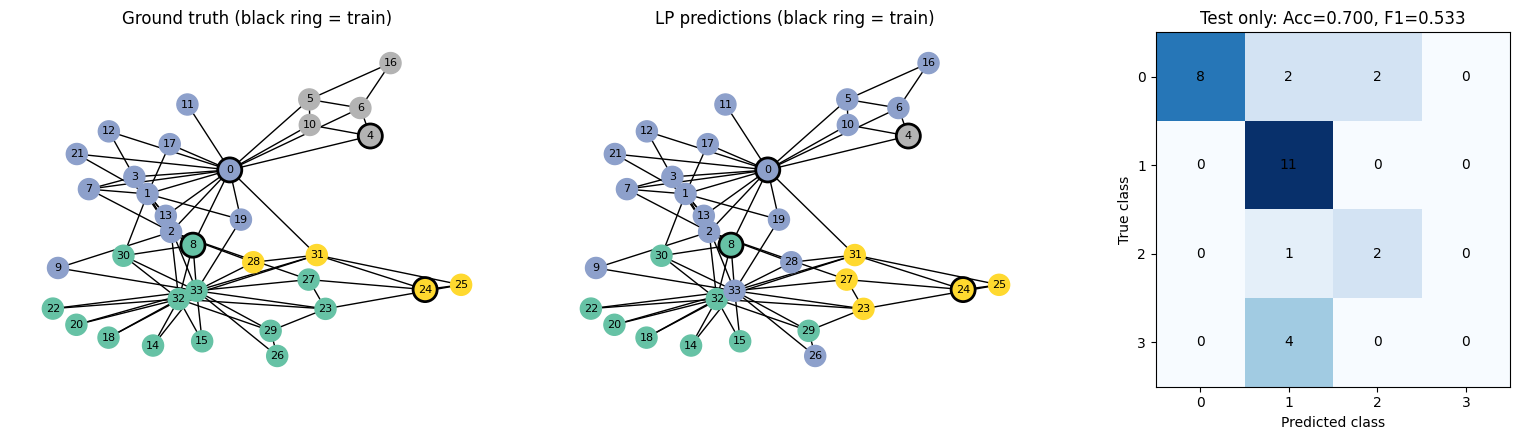

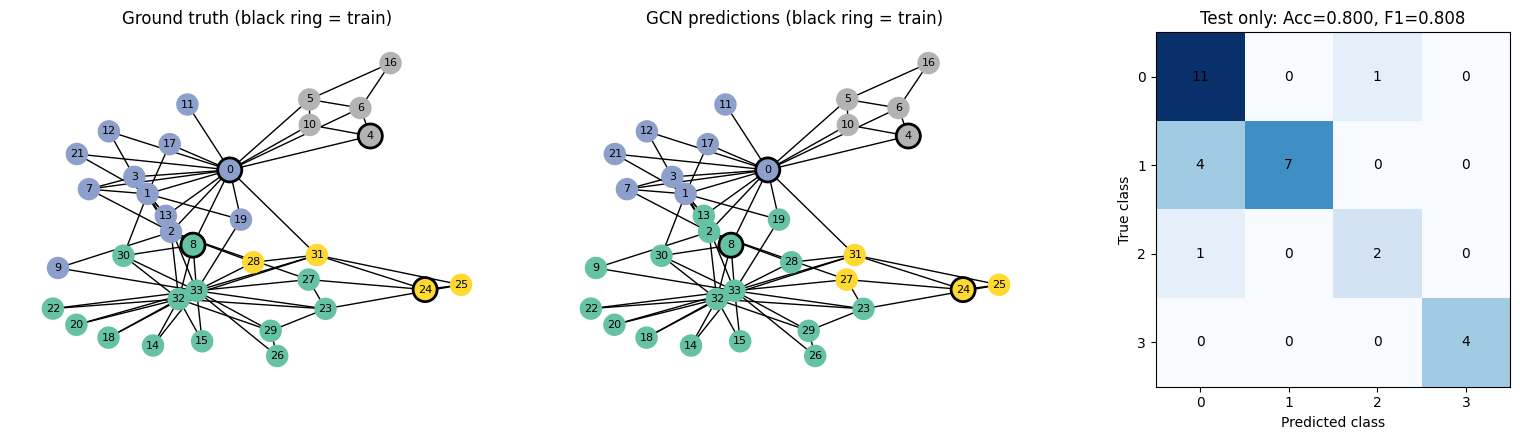

In [7]:
def plot_diagnostics(name, pred):
    report = evaluate(pred, test_mask)
    cm = torch.tensor(report["confusion_matrix"])
    graph = to_networkx(data, to_undirected=True)
    position = nx.spring_layout(graph, seed=42)
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
    display_name = "LP" if name == "LabelPropagation" else name
    for ax, labels, title in [(axes[0], data.y, "Ground truth"),
                              (axes[1], pred, f"{display_name} predictions")]:
        nx.draw_networkx(graph, pos=position, ax=ax, node_color=labels.tolist(),
                         cmap="Set2", vmin=0, vmax=NUM_CLASSES - 1,
                         node_size=230, font_size=8)
        nx.draw_networkx_nodes(graph, position, ax=ax,
                               nodelist=train_mask.nonzero(as_tuple=True)[0].tolist(),
                               node_size=300, node_color="none", edgecolors="black", linewidths=2)
        ax.set_title(title + " (black ring = train)")
        ax.axis("off")
    axes[2].imshow(cm.numpy(), cmap="Blues")
    for row in range(NUM_CLASSES):
        for col in range(NUM_CLASSES):
            axes[2].text(col, row, int(cm[row, col]), ha="center", va="center")
    axes[2].set(xticks=range(NUM_CLASSES), yticks=range(NUM_CLASSES),
                xlabel="Predicted class", ylabel="True class",
                title=f"Test only: Acc={report['accuracy']:.3f}, F1={report['macro_f1']:.3f}")
    fig.tight_layout()
    plt.show()

# 시각화는 사전에 지정한 시드 1234의 결과를 사용합니다.
plot_diagnostics(BASELINE_NAME, examples[BASELINE_NAME]["pred"])
plot_diagnostics("GCN", examples["GCN"]["pred"])


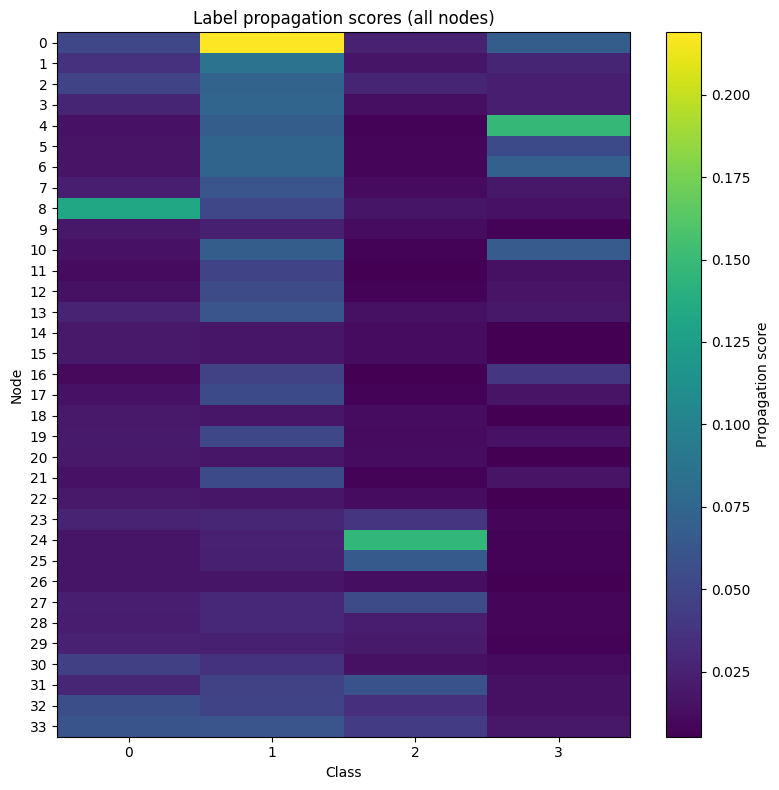

In [8]:
# 결과는 클래스별 전파 점수이며, softmax 확률이나 보정된 확률이 아닙니다.
plt.figure(figsize=(8, 8))
plt.imshow(lp_scores.numpy(), aspect="auto", cmap="viridis")
plt.xticks(range(NUM_CLASSES))
plt.yticks(range(data.num_nodes))
plt.xlabel("Class")
plt.ylabel("Node")
plt.title("Label propagation scores (all nodes)")
plt.colorbar(label="Propagation score")
plt.tight_layout()
plt.show()


## 결과 저장

실행별 지표, 대표 시드의 노드별 예측, 설정 및 패키지 버전을 `results` 아래에 저장합니다. 재실행하면 해당 비교군의 결과를 갱신합니다.


In [9]:
# 커널 작업 위치가 프로젝트 루트/튜토리얼 폴더인 경우 모두 지원합니다.
project_dir = Path.cwd()
if (project_dir / "KETI_AI_Tutorial" / "Karate_club_gcn.ipynb").exists():
    project_dir = project_dir / "KETI_AI_Tutorial"
output_dir = project_dir / "results" / BASELINE_NAME.lower()
output_dir.mkdir(parents=True, exist_ok=True)
with (output_dir / "metrics.csv").open("w", newline="", encoding="utf-8") as handle:
    writer = csv.DictWriter(handle, fieldnames=list(rows[0]))
    writer.writeheader()
    writer.writerows(rows)
with (output_dir / "predictions_seed1234.csv").open("w", newline="", encoding="utf-8") as handle:
    writer = csv.writer(handle)
    writer.writerow(["node", "split", "true_label", "baseline_pred", "gcn_pred"])
    for node in range(data.num_nodes):
        writer.writerow([node, "train" if train_mask[node] else "test", int(data.y[node]),
                         int(examples[BASELINE_NAME]["pred"][node]), int(examples["GCN"]["pred"][node])])
payload = {
    "baseline": BASELINE_NAME, "seeds": SEEDS, "epochs": EPOCHS, "lr": LEARNING_RATE,
    "train_nodes": train_mask.nonzero(as_tuple=True)[0].tolist(),
    "test_nodes": test_mask.nonzero(as_tuple=True)[0].tolist(),
    "versions": {"python": platform.python_version(), "torch": torch.__version__,
                 "torch_geometric": torch_geometric.__version__},
    "baseline_config": BASELINE_CONFIG, "summary": summary,
    "test_reports_seed1234": {name: evaluate(item["pred"], test_mask) for name, item in examples.items()},
}
(output_dir / "summary.json").write_text(json.dumps(payload, ensure_ascii=False, indent=2), encoding="utf-8")
print("Saved:", output_dir.resolve())


Saved: C:\Users\KETI\Desktop\KETI_kjsong\2.Code\KETI_AI_Tutorial\results\labelpropagation
